In [1]:
import sys
import asyncio
from dotenv import load_dotenv
load_dotenv()

# Fix for Windows issues in Jupyter notebooks
if sys.platform == "win32":
    # 1. Use ProactorEventLoop for subprocess support
    if not isinstance(asyncio.get_event_loop_policy(), asyncio.WindowsProactorEventLoopPolicy):
        asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())

    # 2. Redirect stderr to avoid fileno() error when launching MCP servers
    if "ipykernel" in sys.modules:
        sys.stderr = sys.__stderr__

# MCP (Model Context Protocol)

MCP (Model Context Protocol) 是由 Anthropic 推出的开放标准，用于便捷的将AI应用连接外部系统。

在没有MCP的时候，必须手动定义工具，用工具实现文件操作、web搜索、查询航班、查询天气等功能，从而让AI连接外部系统。
但全世界有各种不同的服务，不同服务接口不同，定义Tool非常麻烦。

MCP就像是AI世界的USB接口协议：
- 所有外部服务提供者都可以遵循MCP协议提供Tool
- AI应用基于MCP协议对接任意遵循MCP的外部服务，无需自己定义Tool，实现了工具的快速插拔


## 1.MCP核心概念

| 概念             | 说明                                       |
|----------------|------------------------------------------|
| **MCP Server** | 提供MCP服务的应用，可以是远程服务，也可以是本地服务              |
| **MCP Client** | 连接到MCP服务器，读取MCP信息（特别是Tool信息），供Host使用     |
| **MCP Host**   | 协调和管理多个MCP Client的AI应用，比如LangChain的Agent |

例如，一个AI应用，包含一个操作本地文件的MCP、一个访问数据库的MCP、一个访问外部服务的MCP

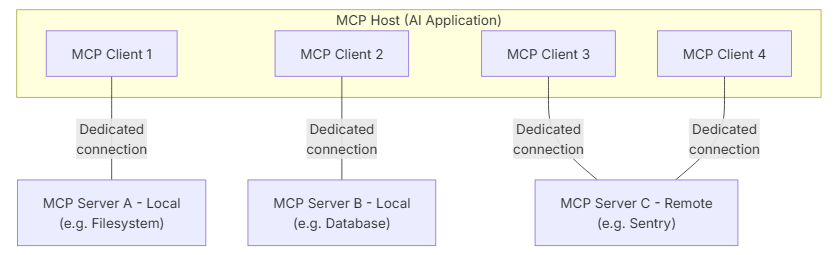


详细的MCP说明可以参考Anthropic公司的MCP官方文档：
https://modelcontextprotocol.io/docs/getting-started/intro

LangChain本身实现了对MCP的支持，本节我们就来学习如何在LangChain中使用MCP


## 2. 连接外部MCP服务

很多提供云服务的公司都提供了MCP服务，例如：
- Amap Maps : 高德地图提供的MCP
- Filesystem : 可以操作文件系统的MCP
- Time : 查询当前时间的MCP服务
- Kiwi : 查询航班、预定航班的MCP服务
- ...

大家可以在mcp.so搜索各种MCP服务：https://mcp.so/

找好自己想要使用的MCP服务后，就可以用LangChain来对接了。

首先，我们需要安装LangChain的MCP依赖库:
```
uv add langchain-mcp-adapters
```

接下来，就可以利用MCP提供的工具来创建Agent了。


### 2.1 Time MCP服务

Time是一个提供时间和时区转换功能的模型上下文协议服务器。此服务器使语言模型能够获取当前时间信息，并使用 IANA 时区名称执行时区转换，同时具备自动检测系统时区的功能。

需要注意的是，Time MCP是基于stdio的通信方式，也就是把这个MCP服务的脚本下载到本地，然后作为一个子进程运行。此时Agent与MCP服务之间的通信就是进程通信，没有网络延迟。

MCP脚本下载的方式取决于Command，常见的有两种：
- npx : 基于node.js的包管理工具
- uvx : 基于uv(python的uv工具)的包管理工具

因此，你的本地环境必须支持npx、uvx命令

In [2]:
from langchain_mcp_adapters.client import MultiServerMCPClient

# 1.获取工具
# 1.1.定义mcp client， 连接Time MCP服务器
client = MultiServerMCPClient(
    {
        "time": {
            "transport": "stdio",
            "command": "uvx",
            "args": [
                "mcp-server-time",
                "--local-timezone=Asia/Shanghai"
            ]
        }
    }
)

# 1.2.用client拉取tool，注意MultiServerMCPClient是异步的，需要await
tools = await client.get_tools()


/workspaces/Python/Agent-SSS/.venv/lib/python3.14/site-packages/langchain_core/utils/pydantic.py:42: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


ImportError: cannot import name 'RequestContext' from 'mcp.shared.context' (/workspaces/Python/Agent-SSS/.venv/lib/python3.14/site-packages/mcp/shared/context.py)

In [ ]:
for tool in tools:
    print(tool.name)
    print(tool.description)
    print("-----------------------")

get_current_time
Get current time in a specific timezone
-----------------------
convert_time
Convert time between timezones
-----------------------
get_time_ago
Get the time a given number of days, hours, minutes and seconds ago in a specific timezone
-----------------------


In [ ]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
import os


# 2.初始化模型
model = init_chat_model(
    model="kimi-k3.1-pro",  # 换成你在百炼开通的模型名称，例如 qwen-max
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    extra_body={"thinking": {"type": "disabled"}}

)


# 3.创建Agent
agent = create_agent(model, tools)

In [ ]:
from langchain_core.messages import HumanMessage

response = await agent.ainvoke({
    "messages": [HumanMessage("现在几点了？")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

现在几点了？
================================== Ai Message ==================================

我来帮你查一下当前时间。
Tool Calls:
  get_current_time (get_current_time_0_a548c82d)
 Call ID: get_current_time_0_a548c82d
  Args:
================================= Tool Message =================================
Name: get_current_time

[{'type': 'text', 'text': '{\n  "timezone": "Asia/Shanghai",\n  "datetime": "2026-11-12T14:42:46+08:00",\n  "day_of_week": "Thursday",\n  "is_dst": false\n}', 'id': 'lc_408fc33a-c26a-4f23-87ec-c0a612b54351'}]
================================== Ai Message ==================================

现在是 **2026年11月12日（星期四）14:42:46**，时区为 **Asia/Shanghai（北京时间，UTC+8）**。


### 2.2 Kiwi MCP服务

Kiwi Travel MCP 将 Kiwi.com 的航班搜索功能直接引入到 AI 对话中。支持单程/往返、灵活日期、多名乘客以及所有舱位等级。

注意：Kiwi服务是基于http的通信方式，也就是说MCP client通过发送http请求与MCP server交互。存在网络延迟。

In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient

# 连接Kiwi MCP服务器
client = MultiServerMCPClient(
    {
        "kiwi-com-flight-search": {
            "transport": "http",
            "url": "https://mcp.kiwi.com"
        },
        "time": {
            "transport": "stdio",
            "command": "uvx",
            "args": [
                "mcp-server-time",
                "--local-timezone=Asia/Shanghai"
            ]
        }
    }
)

# 注意MultiServerMCPClient是异步的，结果都是协程对象，需要await
tools = await client.get_tools()

In [ ]:
for tool in tools:
    print(tool.name)
    print(tool.description)
    print(tool.args_schema)
    print("------------------------------")

search-flight
# Search for flights

Searches Kiwi.com for available flights between two locations for the given dates and passengers. City or airport names are resolved automatically, so call this whenever the user wants to search for flights — whether they gave IATA codes or just place names.

## Result shape

Returns `{ query, currency, passengers, resultsCount, itineraries, searchTimeMs }`. Each item in `itineraries` has:
- `tripType` — `"oneway"` or `"return"`
- `price` (number) and `priceFormatted` (e.g. "123 EUR")
- `totalDurationSeconds`
- `bookingUrl` — the link to book the flight
- `imageId` — destination city id for a hero photo (https://images.kiwi.com/photos/600x600/{imageId}.jpg)
- `baggage` — total included baggage across all travelers: `{ personalItem, cabinBag, checkedBag }` (counts)
- `outbound` (and `inbound` for return flights), each a leg with: `route` (list of airport codes including layovers, e.g. ["PRG","MAD","BCN"]), `departureTime` / `arrivalTime` (local ISO ti

In [ ]:
from langchain.agents import create_agent

# 注意，由于Kiwi中有地域参数（locale），但Tool描述中没说清楚，中文有两种：zh-cn,zh-tw，需要在系统提示词中说明，否则AI默认会传入zh，导致报错
agent = create_agent(
    model=model,
    tools=tools,
    system_prompt="你是一名旅行Agent。帮助用户找到最好的航班。不要追问用户问题。如果用户使用中文，则使用zh-cn作为区域设置值。"
)

In [ ]:
from langchain_core.messages import HumanMessage

response = await agent.ainvoke({
    "messages": [HumanMessage("查一下明天从烟台飞上海的航班。")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

查一下明天从烟台飞上海的航班。
================================== Ai Message ==================================

我先确认明天的日期，然后为您查询烟台到上海的航班。
Tool Calls:
  get_current_time (get_current_time_0_f4436a7e)
 Call ID: get_current_time_0_f4436a7e
  Args:
    timezone: Asia/Shanghai
================================= Tool Message =================================
Name: get_current_time

[{'type': 'text', 'text': '{\n  "timezone": "Asia/Shanghai",\n  "datetime": "2026-11-12T14:47:38+08:00",\n  "day_of_week": "Thursday",\n  "is_dst": false\n}', 'id': 'lc_34d3f08a-41ab-4f8d-8aa2-d039bb997978'}]
================================== Ai Message ==================================

明天是2026年11月13日（星期五）。现在为您查询烟台到上海的航班。
Tool Calls:
  search-flight (search-flight_1_fabbcbeb)
 Call ID: search-flight_1_fabbcbeb
  Args:
    flyFrom: 烟台
    flyTo: 上海
    departureDate: 13/11/2026
    locale: zh-cn
    adults_hand_bags: [1]
=========================

说明：Kiwi更擅长搜索国际航班，如果是国内航班更建议大家基于携程官方API开发Tool来实现航班搜索。

另外，有一个替代的国内航班查询MCP服务，地址是：https://mcp.variflight.com/

不过这个服务是收费的，而且价格比较贵，即便是优惠过后也需要0.1元/次。

使用步骤是：
- 注册账号
- 申请API Key
- 接入MCP

示例：

In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient

# 连接Kiwi MCP服务器
client = MultiServerMCPClient(
    {
        "VariFlight-Aviation": {
            "transport": "http",
            "url": "https://ai.variflight.com/servers/aviation/mcp/?api_key=您在飞友AI开放平台申请的Key"
        }
    }
)

tools = await client.get_tools()

agent = create_agent(
    model="deepseek-chat",
    tools=tools,
    system_prompt="You are a travel agent. Help user find best flights. No follow up questions."
)

response = await agent.ainvoke({
    "messages": [HumanMessage("查一下2026年5月15日晚上从北京飞杭州的航班。")]
})

for message in response["messages"]:
    message.pretty_print()

### 2.3 总结

MCP服务有两种通信方式：
- stdio : 将MCP server作为子进程，通过stdin/stdout通信
- http: 通过http方式与MCP server通信，适合于第三方远程服务，支持SSE


## 3. 自定义MCP Server

在公司内部，不同团队之间也可以把自己团队的服务开发成MCP Server，供他人使用。

### 3.1 创建简单的MCP服务器

自定义MCP最简单的方式就是使用FastMCP了。
首先，需要安装依赖：
```
uv add fastmcp
```
接着，只需要定义几个方法，然后利用FastMCP提供的装饰器即可：
- @mcp.tool : 作为MCP中的工具
- @mcp.resources : 返回MCP需要的resources
- @mcp.prompt : 返回MCP预定义的Prompt

通常我们只需要定义带有tool的MCP Server就可以了。


In [ ]:
from fastmcp import FastMCP

# 初始化mcp
mcp1 = FastMCP("Math")
# 注意：：这个命名用于后续的注释


# mcp tools
@mcp1.tool()
def add(a: float, b: float) -> float:
    """Add two numbers"""
    return a + b


@mcp1.tool()
def multiply(a: float, b: float) -> float:
    """Multiply two numbers"""
    return a * b


@mcp1.tool
def square_root(x: float) -> float:
    """Calculate the square root of a number"""
    return x ** 0.5


# 启动mcp服务，通信方式设置为stdio
if __name__ == "__main__":
    mcp1.run(transport="stdio")

RuntimeError: Already running asyncio in this thread

### 3.2.连接接自定义MCP服务

注意：由于我们自定义的MCP是本地py文件，所以启动的Command直接就是python，而不是npx或uvx


In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient
# 因为我们需要使用client启动MCP本地服务，所以前面不要手动    mcp1.run(transport="stdio")  否则报错


# 连接自定义MCP服务
client = MultiServerMCPClient(
    {
        "math": {
            "transport": "stdio",
            "command": "python",
            "args": ["math_mcp_server.py"]
# 这段配置本质上是让 MultiServerMCPClient 启动一个子进程，相当于在终端运行：
# python math_mcp_server.py

        }
    }
)

tools = await client.get_tools()

for tool in tools:
    print(tool.name)
    print(tool.description)
    print("=================================")

ImportError: cannot import name 'RequestContext' from 'mcp.shared.context' (/workspaces/Python/Agent-SSS/.venv/lib/python3.14/site-packages/mcp/shared/context.py)

In [ ]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=tools,
    system_prompt="You are a helpful agent. You must use tools to answer math question."
)

In [ ]:
from langchain_core.messages import HumanMessage

response = await agent.ainvoke({
    "messages": [HumanMessage("467和529的平方根之和是多少?")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

467和529的平方根之和是多少?
================================== Ai Message ==================================

I'll calculate the square roots of 467 and 529, then add them together.
Tool Calls:
  square_root (call_00_2cBX3OPCYtzS6o9oBF1G4619)
 Call ID: call_00_2cBX3OPCYtzS6o9oBF1G4619
  Args:
    x: 467
  square_root (call_01_H5ZfXptayVuEv6VphWeF5986)
 Call ID: call_01_H5ZfXptayVuEv6VphWeF5986
  Args:
    x: 529
================================= Tool Message =================================
Name: square_root

[{'type': 'text', 'text': '21.61018278497431', 'id': 'lc_78f68986-03b1-45f7-ba31-f8dbd386c13e'}]
================================= Tool Message =================================
Name: square_root

[{'type': 'text', 'text': '23.0', 'id': 'lc_08243523-6d0e-4c94-815c-1c4c593f2bad'}]
================================== Ai Message ==================================

Now I'll add the two square roots together:
Tool 

## 4. 总结

### 核心要点

1. **MCP是什么**
   - 开放协议，标准化LLM应用获取工具的方式
   - 客户端-服务器架构

2. **连接方式**
   - STDIO: 本地MCP服务器
   - HTTP: 远程MCP服务器

3. **使用流程**
   - 配置MultiServerMCPClient
   - 调用get_tools()获取工具
   - 创建Agent并调用

4. **自定义MCP Server**
   - 导入FastMCP
   - 使用@mcp.tool装饰函数，定义工具（必备）
   - 使用@mcp.resource装饰函数，返回resources（可选）
   - 使用@mcp.prompt装饰函数，返回Prompt（可选）
   - 使用mcp.run()启动MCP服务

---

**更多资源**:
- [LangChain MCP官方文档](https://docs.langchain.com/oss/python/langchain/mcp)
- [MCP协议规范](https://modelcontextprotocol.io/)